# Economics 5040: Dynamic Stochastic Modeling
## Answer Key — Problem Set 1: Intertemporal Choice, Production, and Equilibrium

This notebook gives analytical derivations, executable Python solutions, numerical checks, and concise economic interpretations.

The calculations use only standard numerical tools (`numpy`, `scipy`, and `matplotlib`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar, brentq

np.set_printoptions(precision=8, suppress=True)


# Problem 1. Utility, Rankings, and Intertemporal Preferences

We have

$$
U(c_0,c_1)=\log c_0+\beta\log c_1,\qquad \beta=0.95.
$$

### 1(a) Utility values and ranking

In [2]:
beta = 0.95

def U(c0, c1, beta=beta):
    return np.log(c0) + beta*np.log(c1)

plans = {
    "A": (4.0, 4.0),
    "B": (3.0, 6.0),
    "C": (5.0, 3.0)
}

for name, (c0, c1) in plans.items():
    print(name, U(c0, c1))

ranking = sorted(plans, key=lambda n: U(*plans[n]), reverse=True)
print("Ranking:", " > ".join(ranking))


A 2.7032740041837866
B 2.8007837844347616
C 2.6531195866688044
Ranking: B > A > C


The numerical utilities are approximately

$$
U(A)=2.703274,\qquad
U(B)=2.800784,\qquad
U(C)=2.653120.
$$

Hence

$$
\boxed{B\succ A\succ C.}
$$

### 1(b) A monotone transformation

In [3]:
def V(c0, c1, beta=beta):
    return np.exp(U(c0, c1, beta))

for name, (c0, c1) in plans.items():
    print(name, V(c0, c1))

ranking_v = sorted(plans, key=lambda n: V(*plans[n]), reverse=True)
print("Ranking under V:", " > ".join(ranking_v))


A 14.928527864588917
B 16.457540881712898
C 14.198262339602387
Ranking under V: B > A > C


Because the exponential function is strictly increasing,

$$
U(x)>U(y)\quad\Longleftrightarrow\quad e^{U(x)}>e^{U(y)}.
$$

Thus $V=\exp(U)$ represents exactly the same preferences. Utility numbers themselves are not economically meaningful; their ordering is.

### 1(c) Numerical verification on a grid

In [4]:
grid = np.linspace(0.25, 10.0, 100)
c0g, c1g = np.meshgrid(grid, grid)
Ug = U(c0g, c1g).ravel()
Vg = np.exp(Ug)

# Verify that sorting by U gives the same ordering as sorting by V
same_order = np.array_equal(np.argsort(Ug), np.argsort(Vg))
print("Same ordering on 10,000 grid points:", same_order)

# A second check on random pairs
rng = np.random.default_rng(5040)
idx1 = rng.integers(0, len(Ug), size=50000)
idx2 = rng.integers(0, len(Ug), size=50000)

violations = np.sum((Ug[idx1] > Ug[idx2]) & ~(Vg[idx1] > Vg[idx2]))
print("Violations among 50,000 random comparisons:", violations)


Same ordering on 10,000 grid points: True
Violations among 50,000 random comparisons: 0


There should be no violations. This is a numerical illustration of the ordinal nature of utility representation.

### 1(d) Time separability

For

$$
U(c_0,c_1,c_2)
=
\log c_0+\beta\log c_1+\beta^2\log c_2,
$$

the marginal utilities are

$$
U_{c_1}=\frac{\beta}{c_1},
\qquad
U_{c_2}=\frac{\beta^2}{c_2}.
$$

Hence the marginal rate of substitution between lunch and dinner is

$$
MRS_{1,2}
=
\frac{U_{c_1}}{U_{c_2}}
=
\frac{c_2}{\beta c_1}.
$$

Notice that $c_0$ does not appear. Under time separability, the subjective tradeoff between lunch and dinner is independent of breakfast consumption. That is analytically convenient but behaviorally restrictive: after an unusually large breakfast, one would normally expect the desirability of lunch relative to dinner to change.

# Problem 2. A Two-Period Exchange Economy

Endowment:

$$
(e_0,e_1)=(4,6),
\qquad \beta=0.96.
$$

The present-value budget constraint is

$$
c_0+\frac{c_1}{R}
=
e_0+\frac{e_1}{R}.
$$

Equivalently,

$$
c_1=R(e_0-c_0)+e_1,
$$

so the budget line has slope $-R$. One unit of current consumption costs $R$ units of future consumption; equivalently, one unit of future consumption costs $1/R$ units of current consumption.

### 2(b) Analytical and numerical solution for $R=1.10$

The first-order condition is

$$
\frac{1/c_0}{\beta/c_1}=R,
$$

so

$$
c_1=\beta R c_0.
$$

Let

$$
W=e_0+\frac{e_1}{R}.
$$

Substituting the first-order condition into the budget constraint gives

$$
c_0^*=\frac{W}{1+\beta},
\qquad
c_1^*=\frac{\beta R W}{1+\beta}.
$$

In [5]:
e0, e1 = 4.0, 6.0
beta2 = 0.96
R = 1.10

W = e0 + e1/R
c0_star = W/(1+beta2)
c1_star = beta2*R*W/(1+beta2)
s_star = e0 - c0_star
mrs = c1_star/(beta2*c0_star)

print("W =", W)
print("c0* =", c0_star)
print("c1* =", c1_star)
print("saving =", s_star)
print("MRS =", mrs)
print("R =", R)

def neg_utility_c0(c0):
    c1 = R*(e0-c0) + e1
    if c0 <= 0 or c1 <= 0:
        return np.inf
    return -(np.log(c0) + beta2*np.log(c1))

res = minimize_scalar(neg_utility_c0, bounds=(1e-9, e0+e1/R-1e-9),
                      method="bounded")
c0_num = res.x
c1_num = R*(e0-c0_num) + e1

print("\nNumerical optimizer:")
print("c0 =", c0_num)
print("c1 =", c1_num)


W = 9.454545454545453
c0* = 4.823747680890538
c1* = 5.093877551020408
saving = -0.8237476808905377
MRS = 1.1
R = 1.1

Numerical optimizer:
c0 = 4.8237477255324555
c1 = 5.0938775019142986


Numerically,

$$
c_0^*\approx 4.824675,\qquad
c_1^*\approx 5.129896.
$$

Thus

$$
s=e_0-c_0^*\approx -0.824675.
$$

The household is a borrower: it consumes more than its current endowment and repays by giving up some future consumption.

### 2(c) Budget set, endowment, optimum, and indifference curve

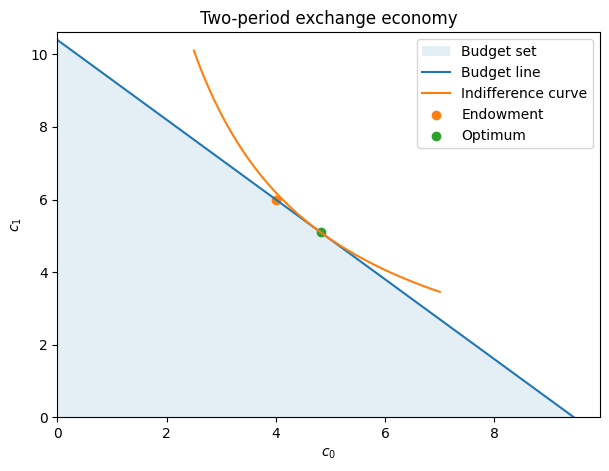

In [6]:
R = 1.10
W = e0 + e1/R
c0_star = W/(1+beta2)
c1_star = beta2*R*W/(1+beta2)
u_star = np.log(c0_star) + beta2*np.log(c1_star)

c0_line = np.linspace(0.001, W, 500)
c1_budget = R*(W-c0_line)

# Indifference curve -- only plot the economically relevant portion
c0_ic = np.linspace(2.5, 7.0, 500)
c1_ic = np.exp((u_star - np.log(c0_ic))/beta2)

plt.figure(figsize=(7,5))
plt.fill_between(c0_line, 0, c1_budget, alpha=0.12, label="Budget set")
plt.plot(c0_line, c1_budget, label="Budget line")
plt.plot(c0_ic, c1_ic, label="Indifference curve")
plt.scatter([e0], [e1], label="Endowment")
plt.scatter([c0_star], [c1_star], label="Optimum")
plt.xlim(0, W*1.05)
plt.ylim(0, max(R*W, np.nanmax(c1_ic[np.isfinite(c1_ic)]))*1.02)
plt.xlabel(r"$c_0$")
plt.ylabel(r"$c_1$")
plt.legend()
plt.title("Two-period exchange economy")
plt.show()


### 2(d) Comparative statics with respect to $R$

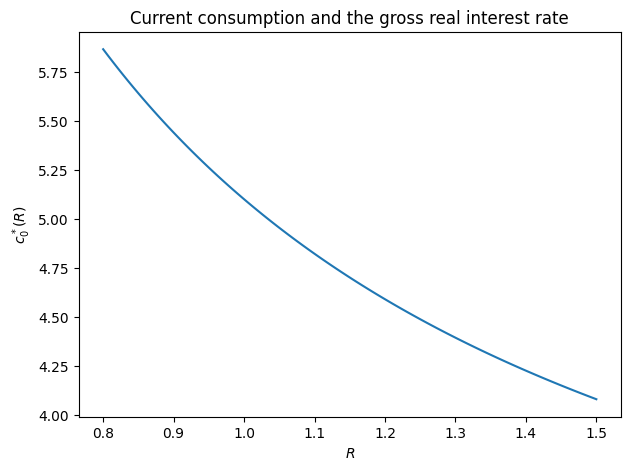

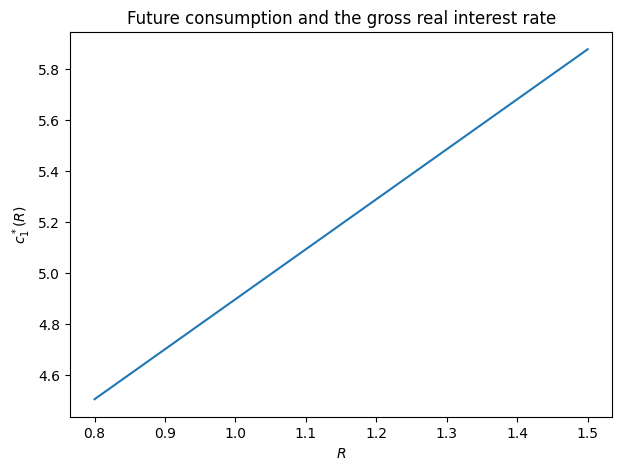

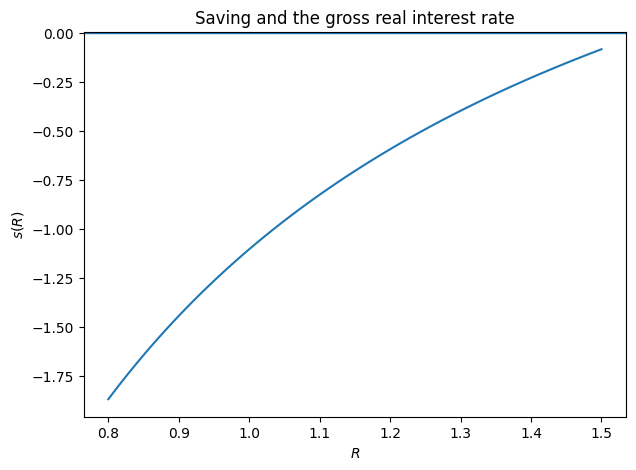

In [7]:
R_grid = np.linspace(0.8, 1.5, 100)
W_grid = e0 + e1/R_grid
c0_grid = W_grid/(1+beta2)
c1_grid = beta2*R_grid*W_grid/(1+beta2)
s_grid = e0 - c0_grid

plt.figure(figsize=(7,5))
plt.plot(R_grid, c0_grid)
plt.xlabel(r"$R$")
plt.ylabel(r"$c_0^*(R)$")
plt.title("Current consumption and the gross real interest rate")
plt.show()

plt.figure(figsize=(7,5))
plt.plot(R_grid, c1_grid)
plt.xlabel(r"$R$")
plt.ylabel(r"$c_1^*(R)$")
plt.title("Future consumption and the gross real interest rate")
plt.show()

plt.figure(figsize=(7,5))
plt.plot(R_grid, s_grid)
plt.axhline(0, linewidth=1)
plt.xlabel(r"$R$")
plt.ylabel(r"$s(R)$")
plt.title("Saving and the gross real interest rate")
plt.show()


For log preferences,

$$
c_0^*(R)=\frac{e_0+e_1/R}{1+\beta},
$$

which falls with $R$ when $e_1>0$, while

$$
c_1^*(R)=\frac{\beta(Re_0+e_1)}{1+\beta},
$$

which rises with $R$ when $e_0>0$.

A higher $R$ makes future consumption cheaper relative to current consumption, generating a substitution toward the future. It also changes the present value of the endowment: because the household owns future goods, a higher $R$ lowers their present value. The observed response combines these substitution and wealth effects.

### 2(e) Interest rate at which the household chooses its endowment

At the endowment, optimality requires

$$
R=\frac{u'(e_0)}{\beta u'(e_1)}
=
\frac{e_1}{\beta e_0}.
$$

Therefore

$$
\widehat R
=
\frac{6}{0.96\times4}
=
1.5625.
$$

At this interest rate the budget line is tangent to the household's indifference curve exactly at its endowment, so it has no desire to borrow or lend.

In [8]:
R_hat = e1/(beta2*e0)
print(R_hat)


1.5625


# Problem 3. Intertemporal Production and the Planner

The planner solves

$$
\max_{c_0,c_1,k_0}
\left\{\log c_0+\beta\log c_1\right\}
$$

subject to

$$
c_0+k_0\le y_0,
\qquad
c_1\le A k_0^\alpha,
\qquad
c_0,c_1,k_0\ge0.
$$

Because utility is increasing, both resource constraints bind. Hence

$$
c_0=y_0-k_0,\qquad c_1=A k_0^\alpha,
$$

and the problem reduces to

$$
\max_{0<k_0<y_0}
\left\{
\log(y_0-k_0)
+\beta\log(Ak_0^\alpha)
\right\}.
$$

### 3(b) First-order condition

Differentiating,

$$
-\frac{1}{y_0-k_0}
+
\beta\frac{\alpha}{k_0}
=0.
$$

Equivalently,

$$
\frac{1/c_0}{\beta/c_1}
=
A\alpha k_0^{\alpha-1}.
$$

Thus

$$
\boxed{MRS=MRT}.
$$

The left side is

$$
MRS=\frac{c_1}{\beta c_0},
$$

and the right side is

$$
MRT=f'(k_0)=A\alpha k_0^{\alpha-1}.
$$

### 3(c) Analytical and numerical planner solution

From

$$
\frac{1}{y_0-k_0}=\frac{\beta\alpha}{k_0},
$$

we obtain

$$
k_0^*=\frac{\beta\alpha}{1+\beta\alpha}y_0,
$$

and therefore

$$
c_0^*=\frac{y_0}{1+\beta\alpha},
\qquad
c_1^*=A(k_0^*)^\alpha.
$$

In [9]:
y0 = 10.0
Aprod = 2.5
alpha = 0.4
beta3 = 0.95

k_star = beta3*alpha*y0/(1+beta3*alpha)
c0_star3 = y0-k_star
c1_star3 = Aprod*k_star**alpha
R_star3 = Aprod*alpha*k_star**(alpha-1)

print("k*  =", k_star)
print("c0* =", c0_star3)
print("c1* =", c1_star3)
print("MRT =", R_star3)
print("MRS =", c1_star3/(beta3*c0_star3))

def planner_neg(k):
    if k <= 0 or k >= y0:
        return np.inf
    return -(np.log(y0-k) + beta3*np.log(Aprod*k**alpha))

res3 = minimize_scalar(planner_neg, bounds=(1e-10, y0-1e-10),
                       method="bounded",
                       options={"xatol":1e-13})
print("\nNumerical k* =", res3.x)
print("absolute error =", abs(res3.x-k_star))


k*  = 2.7536231884057973
c0* = 7.246376811594203
c1* = 3.7488823625207948
MRT = 0.5445744905556522
MRS = 0.5445744905556523

Numerical k* = 2.75362310573043
absolute error = 8.267536744099857e-08


The analytical solution is approximately

$$
\boxed{k_0^*=2.75362319},
$$

$$
\boxed{c_0^*=7.24637681},
$$

$$
\boxed{c_1^*=3.74888236}.
$$

The common marginal tradeoff is

$$
MRS=MRT\approx0.54457449.
$$

### 3(d) PPF, planner optimum, indifference curve, and supporting tangent

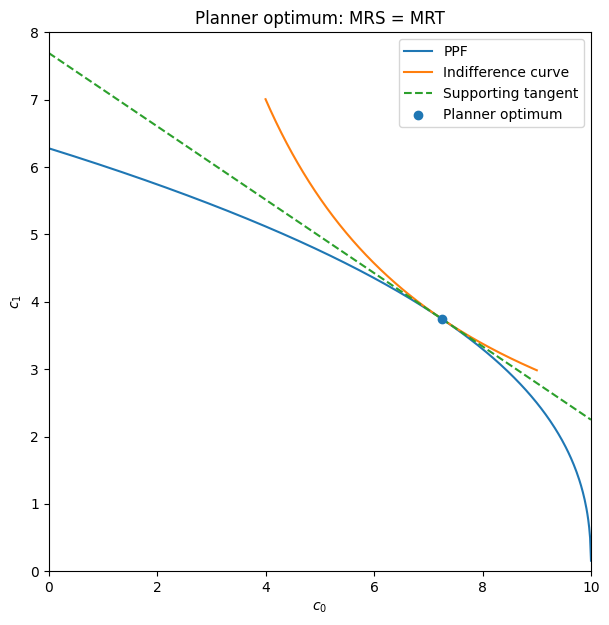

Slope of PPF at optimum = -0.5445744905556522
Slope of indifference curve at optimum = -0.5445744905556523
Slope of supporting line = -0.5445744905556522


In [10]:
# Values for the production possibility frontier
c0_vals = np.linspace(0.001, y0 - 0.001, 600)
ppf = Aprod * (y0 - c0_vals)**alpha

# Utility at the planner's optimum
u_star3 = np.log(c0_star3) + beta3 * np.log(c1_star3)

# Plot only the economically relevant part of the indifference curve
c0_ic = np.linspace(4.0, 9.0, 500)
c1_ic = np.exp((u_star3 - np.log(c0_ic)) / beta3)

# Supporting tangent line at the planner's optimum
tangent = c1_star3 - R_star3 * (c0_vals - c0_star3)

# Figure
plt.figure(figsize=(7, 7))

plt.plot(c0_vals, ppf,
         label="PPF")

plt.plot(c0_ic, c1_ic,
         label="Indifference curve")

plt.plot(c0_vals, tangent,
         linestyle="--",
         label="Supporting tangent")

plt.scatter([c0_star3], [c1_star3],
            label="Planner optimum",
            zorder=5)

plt.xlabel(r"$c_0$")
plt.ylabel(r"$c_1$")

plt.xlim(0, 10)
plt.ylim(0, 8)

plt.legend()
plt.title("Planner optimum: MRS = MRT")

plt.show()

print("Slope of PPF at optimum =",
      -R_star3)

print("Slope of indifference curve at optimum =",
      -c1_star3 / (beta3 * c0_star3))

print("Slope of supporting line =",
      -R_star3)



### 3(e) Patience and investment

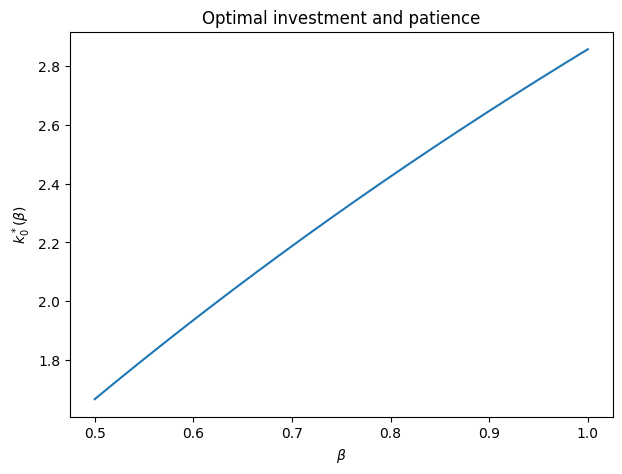

In [11]:
beta_grid = np.linspace(0.50, 1.00, 150)
k_beta = beta_grid*alpha*y0/(1+beta_grid*alpha)

plt.figure(figsize=(7,5))
plt.plot(beta_grid, k_beta)
plt.xlabel(r"$\beta$")
plt.ylabel(r"$k_0^*(\beta)$")
plt.title("Optimal investment and patience")
plt.show()


For this example,

$$
k_0^*(\beta)
=
\frac{\beta\alpha}{1+\beta\alpha}y_0,
$$

so

$$
\frac{dk_0^*}{d\beta}
=
\frac{\alpha y_0}{(1+\beta\alpha)^2}>0.
$$

More patient households invest more.

The monotonicity is not peculiar to log utility and Cobb--Douglas production. Under the standard assumptions that utility is increasing and future production is increasing, the objective

$$
u(y_0-k)+\beta u(f(k))
$$

has increasing differences in $(k,\beta)$, since

$$
\frac{\partial^2}{\partial k\,\partial\beta}
\left[u(y_0-k)+\beta u(f(k))\right]
=
u'(f(k))f'(k)>0.
$$

Hence the optimal investment choice is nondecreasing in $\beta$ (with strict increase under suitable strictness/uniqueness conditions). Concavity guarantees a well-behaved optimum; monotonicity comes from the increasing-differences property.

# Problem 4. Decentralizing the Planner's Allocation

The firm's present-value profit is

$$
\Pi(k_0)=\frac{f(k_0)}{R}-k_0.
$$

Its first-order condition is

$$
\frac{f'(k_0)}{R}-1=0,
$$

or

$$
\boxed{f'(k_0)=R}.
$$

### 4(b) Equilibrium interest rate

In [12]:
R_eq = Aprod*alpha*k_star**(alpha-1)
r_eq = R_eq - 1
print("R* =", R_eq)
print("r* =", r_eq)


R* = 0.5445744905556522
r* = -0.4554255094443478


Thus

$$
\boxed{R^*\approx0.54457449},
\qquad
\boxed{r^*\approx-0.45542551}.
$$

The negative net rate is a consequence of the chosen numerical calibration; it is not a general implication of the model.

### 4(c) Consumer problem with firm ownership

At $R^*$, the firm chooses $k_0^*$. Its present-value profit is

$$
\Pi^*
=
\frac{f(k_0^*)}{R^*}-k_0^*.
$$

Assume the representative household owns the firm. The household's present-value wealth is therefore

$$
W=y_0+\Pi^*.
$$

Its budget constraint is

$$
c_0+\frac{c_1}{R^*}\le y_0+\Pi^*.
$$

With log utility, its demands are

$$
c_0=\frac{W}{1+\beta},
\qquad
c_1=\frac{\beta R^*W}{1+\beta}.
$$

In [13]:
f_star = Aprod*k_star**alpha
pi_star = f_star/R_eq - k_star
W_eq = y0 + pi_star

c0_cons = W_eq/(1+beta3)
c1_cons = beta3*R_eq*W_eq/(1+beta3)

print("firm profit =", pi_star)
print("household PV wealth =", W_eq)
print("consumer c0 =", c0_cons)
print("consumer c1 =", c1_cons)
print("planner c0 =", c0_star3)
print("planner c1 =", c1_star3)


firm profit = 4.130434782608697
household PV wealth = 14.130434782608697
consumer c0 = 7.246376811594204
consumer c1 = 3.748882362520794
planner c0 = 7.246376811594203
planner c1 = 3.7488823625207948


The household's decentralized choice coincides with the planner allocation:

$$
(c_0,c_1)=(c_0^*,c_1^*).
$$

Firm ownership matters because profits are part of household wealth.

### 4(d) Numerical verification of $MRS=R=MRT$

In [14]:
mrs_eq = c1_cons/(beta3*c0_cons)
mrt_eq = Aprod*alpha*k_star**(alpha-1)

print("MRS =", mrs_eq)
print("R   =", R_eq)
print("MRT =", mrt_eq)
print("|MRS-R| =", abs(mrs_eq-R_eq))
print("|R-MRT| =", abs(R_eq-mrt_eq))


MRS = 0.5445744905556521
R   = 0.5445744905556522
MRT = 0.5445744905556522
|MRS-R| = 1.1102230246251565e-16
|R-MRT| = 0.0


### 4(e) Economic interpretation

The planner chooses the allocation directly, subject to feasibility. In the decentralized economy, the household maximizes utility taking $R$ and its wealth as given, while the firm maximizes profit taking $R$ as given. Market clearing requires the household's desired intertemporal trade to be consistent with the firm's desired investment and production.

The key result is that the same price coordinates the two sides:

$$
\underbrace{MRS}_{\text{preferences}}
=
\underbrace{R}_{\text{market price}}
=
\underbrace{MRT}_{\text{technology}}.
$$

Hence the competitive equilibrium implements the planner allocation in this simple economy. This is the basic welfare-theorem logic.

# Problem 5. A Computational Experiment with Disequilibrium

For any $R>0$, the firm solves

$$
A\alpha k^{\alpha-1}=R,
$$

so

$$
k^d(R)=
\left(\frac{A\alpha}{R}\right)^{1/(1-\alpha)}.
$$

Given the firm's optimal profit at that $R$, household present-value wealth is

$$
W(R)=y_0+\Pi(R).
$$

The household chooses

$$
c_0(R)=\frac{W(R)}{1+\beta}.
$$

Define household saving of the date-0 good as

$$
s(R)=y_0-c_0(R).
$$

Then

$$
Z(R)=k^d(R)-s(R).
$$

A competitive equilibrium requires $Z(R)=0$: desired investment equals the date-0 resources the household makes available rather than consuming.

In [15]:
def firm_at_R(R):
    k = (Aprod*alpha/R)**(1/(1-alpha))
    f = Aprod*k**alpha
    pi = f/R - k
    return k, f, pi

def household_at_R(R):
    k, f, pi = firm_at_R(R)
    W = y0 + pi
    c0 = W/(1+beta3)
    c1 = beta3*R*W/(1+beta3)
    s = y0-c0
    return c0, c1, s

def Z(R):
    k, _, _ = firm_at_R(R)
    _, _, s = household_at_R(R)
    return k-s


### 5(b) Excess demand for investment funds

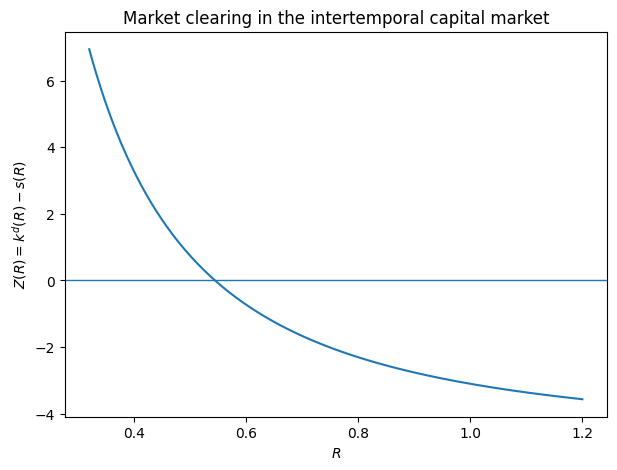

In [16]:
Rz = np.linspace(0.32, 1.2, 400)
Zvals = np.array([Z(R) for R in Rz])

plt.figure(figsize=(7,5))
plt.plot(Rz, Zvals)
plt.axhline(0, linewidth=1)
plt.xlabel(r"$R$")
plt.ylabel(r"$Z(R)=k^d(R)-s(R)$")
plt.title("Market clearing in the intertemporal capital market")
plt.show()


### 5(c) Root finding

In [17]:
R_root = brentq(Z, 0.4, 0.8)
print("root =", R_root)
print("Z(root) =", Z(R_root))


root = 0.5445744905556522
Z(root) = 0.0


A root is an equilibrium because at that price the firm's desired investment exactly equals the household's desired supply of date-0 resources.

### 5(d) Comparison with the planner/decentralization solution

In [18]:
print("Root-finding R =", R_root)
print("Planner/decentralization R* =", R_eq)
print("Difference =", R_root-R_eq)


Root-finding R = 0.5445744905556522
Planner/decentralization R* = 0.5445744905556522
Difference = 0.0


The two values agree up to numerical precision. This is not accidental: $R=f'(k^*)$ is precisely the supporting price that decentralizes the efficient allocation, and market clearing selects that same price.

### 5(e) Low and high interest rates

In [19]:
for Rtest in [0.45, 0.70]:
    k, _, _ = firm_at_R(Rtest)
    _, _, s = household_at_R(Rtest)
    print(f"R={Rtest:.2f}: investment={k:.6f}, saving={s:.6f}, Z={k-s:.6f}")


R=0.45: investment=3.784244, saving=1.960838, Z=1.823406
R=0.70: investment=1.812049, saving=3.477911, Z=-1.665862


At $R=0.45<R^*$, desired investment exceeds household saving, so

$$
Z(R)>0.
$$

There is excess demand for date-0 resources. An increase in $R$ discourages firms from investing and tends to increase the resources households make available, reducing the imbalance.

At $R=0.70>R^*$, desired investment is below household saving, so

$$
Z(R)<0.
$$

There is excess supply of date-0 resources. A fall in $R$ moves the market toward clearing.

# Problem 6. The First Welfare Theorem — What the Computer Does Not Prove

### 6(a) Random feasible allocations

In [20]:
rng = np.random.default_rng(5040)
N = 100_000

# Draw k first, then draw c0 within [0, y0-k], and c1 within [0, f(k)]
k_draw = rng.uniform(1e-8, y0-1e-8, N)
c0_max = y0-k_draw
c1_max = Aprod*k_draw**alpha

c0_draw = rng.uniform(1e-8, 1.0, N)*c0_max
c1_draw = rng.uniform(1e-8, 1.0, N)*c1_max

U_draw = np.log(c0_draw) + beta3*np.log(c1_draw)
best = np.argmax(U_draw)

U_planner = np.log(c0_star3) + beta3*np.log(c1_star3)

print("Best random utility =", U_draw[best])
print("Planner utility =", U_planner)
print("Utility gap =", U_planner-U_draw[best])
print("Best random allocation:",
      c0_draw[best], c1_draw[best], k_draw[best])
print("Planner allocation:",
      c0_star3, c1_star3, k_star)


Best random utility = 3.207338510755032
Planner utility = 3.235886464779406
Utility gap = 0.028547954024373823
Best random allocation: 7.139204687030625 3.695410760191046 2.735925232019171
Planner allocation: 7.246376811594203 3.7488823625207948 2.7536231884057973


### 6(b) Does simulation prove global optimality?

No. A finite random search examines only finitely many feasible allocations. Even 100,000 draws cannot rule out the existence of an unexamined allocation with higher utility. Global optimality here follows from the analytical structure: the feasible set and objective are well behaved, the reduced objective is strictly concave, and its first-order condition identifies the unique global optimum.

### 6(c) Does numerical coincidence prove the First Welfare Theorem?

No. Numerical coincidence in one calibrated model is evidence consistent with the theorem, not a proof of the theorem. The First Welfare Theorem is a general proposition about competitive equilibria under specified assumptions. Its proof must establish the efficiency result for all economies satisfying those assumptions, not merely for one numerical example.

### 6(d) Statement and Pareto efficiency

A simple statement of the First Welfare Theorem is:

> Under the usual competitive-market assumptions, every competitive equilibrium allocation is Pareto efficient.

An allocation is Pareto efficient if there is no feasible alternative that makes at least one person better off without making anyone else worse off. In this one-consumer economy, that reduces to a particularly simple statement: there is no other feasible consumption plan that the consumer strictly prefers.

### 6(e) Why “markets are efficient” is too loose

The slogan hides the theorem's hypotheses. Among other things, the standard result presumes price-taking behavior and sufficiently complete markets for the relevant commodities. Externalities, public goods, market power, asymmetric information, missing contingent claims, or other failures of the competitive-market assumptions can break the connection between competitive equilibrium and Pareto efficiency. Moreover, Pareto efficiency says nothing by itself about the fairness or distributional desirability of the allocation.

# Problem 7. Synthesis — Sample Answer

The gross real interest rate $R$ is the relative price that connects consumption at two different dates. One unit of current consumption sacrificed today can purchase $R$ units of consumption tomorrow. Thus $R$ converts an intertemporal choice problem into an ordinary problem of choosing between two commodities, $c_0$ and $c_1$.

On the household side, preferences determine the subjective rate at which the consumer is willing to exchange current for future consumption. With time-separable utility, an interior optimum satisfies

$$
MRS
=
\frac{u'(c_0)}{\beta u'(c_1)}
=
R.
$$

The household therefore chooses its consumption plan so that its subjective tradeoff equals the market tradeoff.

On the production side, technology determines the rate at which the economy can physically transform current resources into future resources. If current investment is $k_0$ and future output is $f(k_0)$, the marginal rate of transformation is

$$
MRT=f'(k_0).
$$

A competitive firm maximizes present-value profit. Its optimal investment therefore satisfies

$$
f'(k_0)=R.
$$

The same market price is consequently seen by the consumer and the firm. Market clearing selects the value of $R$ for which the household's desired intertemporal trade is consistent with the firm's desired investment. In equilibrium,

$$
\boxed{MRS=R=MRT}.
$$

This equality is important because it coordinates preferences and technology without a planner directly choosing the allocation. The planner would choose current consumption and investment to maximize utility subject to technological feasibility, producing the condition $MRS=MRT$. Competitive markets reproduce this condition indirectly: the household sets $MRS=R$, the firm sets $MRT=R$, and market clearing makes the plans mutually consistent.

This is also the intuition behind the First Welfare Theorem in this simple setting. The competitive allocation is Pareto efficient because there is no feasible reallocation between present and future consumption that can improve the representative consumer's welfare. If $MRS$ differed from $MRT$, a feasible change in investment could improve welfare. At equality, those gains have been exhausted.

Thus the real interest rate is not merely a financial return. It is the equilibrium relative price that transmits information between consumers and producers and coordinates decentralized intertemporal decisions.

# Final Requirement: “What surprised me?” — Example

A strong answer should identify a genuine conceptual surprise. One example is:

> I had previously thought of the interest rate mainly as the reward for saving. The exercise made clear that it has a more fundamental role: it is a relative price between dated commodities. The same $R$ appears in the household's marginal rate of substitution and the firm's marginal productivity condition. That is why an interest rate can coordinate decentralized consumption and investment decisions. I also found it surprising that the equilibrium could be computed either from the planner's tangency condition or as the root of an excess-demand equation; the two procedures are solving the same equilibrium from different directions.

Students need not give this answer, but they should identify something specific and explain what changed in their understanding.